# Global spectroscopic-richness regression
Section 5 reverse conditional, not an inversion of the forward projection model. Run the fitter first. These notebooks never run MCMC.

## Configuration, tables and convergence

In [3]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import emcee
from scipy.stats import norm, chi2, gaussian_kde

ROOT = Path.cwd().resolve()
if ROOT.name == "richness_relation":
    ROOT = ROOT.parent
assert (ROOT / "richness_relation").is_dir(), "Open from the Git repository"
sys.path.insert(0, str(ROOT / "richness_relation"))
from prepare_conditional_richness import load_sample
from global_spec_richness_model import design
from summarize_global_spec_richness import summarize

FITS = ROOT / "catalogs/global_spec_richness"
OUTPUT = ROOT / "plots/global_spec_richness"
OUTPUT.mkdir(parents=True, exist_ok=True)
Z_EDGES = [0.10, 0.18, 0.24, 0.35]
RM_EDGES = [20, 30, 50, 100]  # Diagnostic cells only, not fitting cuts.
COLORS = ["crimson", "darkorange", "royalblue"]
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 12,
                     "axes.labelsize": 16, "axes.linewidth": 1.1})
def style(ax):
    ax.grid(False)
    ax.tick_params(which="both", direction="in", top=True, right=True)
def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUTPUT / f"{name}.{ext}", dpi=200, bbox_inches="tight")

comparison, parameters = summarize(FITS)
display(comparison.drop(columns="sample_sha256"), parameters)
meta = {m: json.loads((FITS / m / "run.json").read_text()) for m in ("noz", "z")}
data, audit = load_sample(meta["noz"]["data_path"])
posterior = {}
for m in meta:
    with np.load(FITS / m / "posterior.npz") as f:
        posterior[m] = f["samples"].copy()
    diag = json.loads((FITS / m / "diagnostics.json").read_text())
    print(m, "CONVERGED:", diag["converged"],
          "minimum N/tau:", np.min(diag["steps_per_tau"]),
          "worst Rhat:", max(diag["rhat_worst"]))
    if not diag["converged"]:
        print("PROVISIONAL: do not use this posterior for final inference.")
rng = np.random.default_rng(42)

model    N  k  log_likelihood_max  chi2_mle  dof          AIC          BIC  converged                                                    sample_sha256  delta_AIC_vs_noz  delta_BIC_vs_noz  delta_chi2_mle_vs_noz
  noz 7345  3       -39615.705478    7345.0 7342 79237.410956 79258.116281       True 73153b3e766836c0eb88ef745bedef5a35c21ce56fff631dd253fc184c988af4          0.000000          0.000000           0.000000e+00
    z 7345  4       -39611.694747    7345.0 7341 79231.389493 79258.996594       True 73153b3e766836c0eb88ef745bedef5a35c21ce56fff631dd253fc184c988af4         -6.021463          0.880313          -9.094947e-13


,model,N,k,log_likelihood_max,chi2_mle,dof,AIC,BIC,converged,delta_AIC_vs_noz,delta_BIC_vs_noz,delta_chi2_mle_vs_noz
0,noz,7345,3,-39615.705478,7345.0,7342,79237.410956,79258.116281,True,0.000000,0.000000,0.000000e+00
1,z,7345,4,-39611.694747,7345.0,7341,79231.389493,79258.996594,True,-6.021463,0.880313,-9.094947e-13


,model,parameter,median,err_minus,err_plus,mle
0,noz,a_rev,4.950294,0.006546,0.006658,4.950289
1,noz,b_rev,0.720379,0.015091,0.015002,0.720149
2,noz,s_rev,0.456131,0.003676,0.003778,0.456085
3,z,a_rev,4.954689,0.006761,0.006942,4.954775
4,z,b_rev,0.720746,0.015146,0.014895,0.720538
5,z,c_rev,-0.293038,0.102404,0.103167,-0.293229
6,z,s_rev,0.455941,0.003717,0.003766,0.455836


noz CONVERGED: True minimum N/tau: 100.70875026082713 worst Rhat: 1.0156536055279892
z CONVERGED: True minimum N/tau: 78.03083635804231 worst Rhat: 1.0208691167362682


## Relation
Hollow markers: geometric means with SEM in log richness. Bands: 68% posterior intervals of the geometric-mean relation, not population scatter. Display limits do not affect the fit.

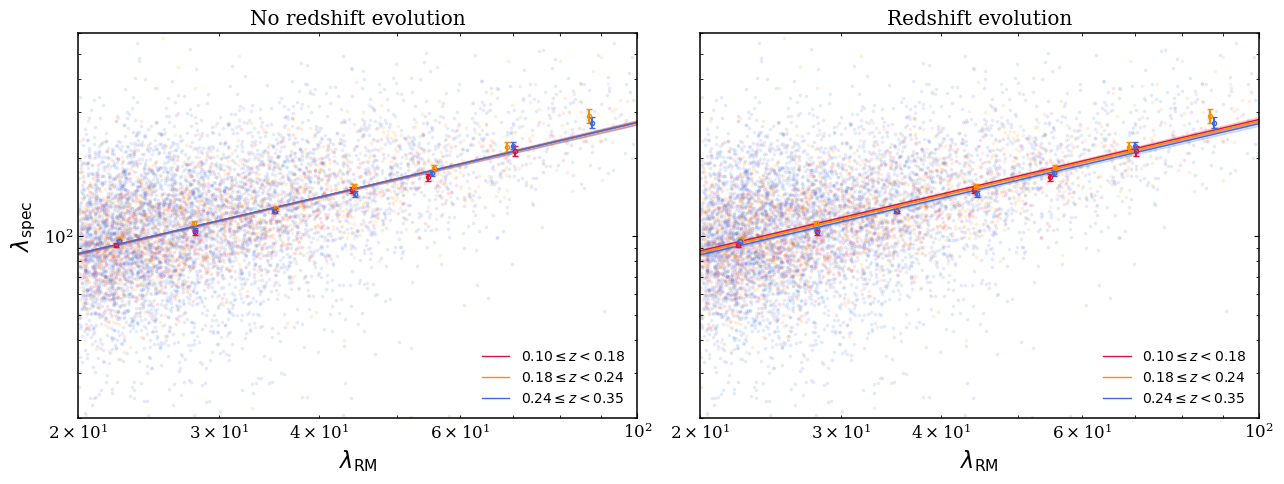

In [4]:
X_LIM, Y_LIM = (20, 100), (20, 600)
MEAN_BINS = np.geomspace(*X_LIM, 8)
MIN_COUNT = 20
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
x, y, z = data["lambda_rm"], data["lambda_spec"], data["z"]
for ax, model in zip(axes, ("noz", "z")):
    for iz, (lo, hi) in enumerate(zip(Z_EDGES[:-1], Z_EDGES[1:])):
        keep = (z >= lo) & (z < hi)
        ax.scatter(x[keep], y[keep], s=3, alpha=0.09, color=COLORS[iz], rasterized=True)
        for left, right in zip(MEAN_BINS[:-1], MEAN_BINS[1:]):
            use = keep & (x >= left) & (x < right)
            if use.sum() < MIN_COUNT:
                continue
            ly = np.log(y[use])
            center, sem = ly.mean(), ly.std(ddof=1) / np.sqrt(use.sum())
            ax.errorbar(np.exp(np.log(x[use]).mean()), np.exp(center),
                        yerr=[[np.exp(center)-np.exp(center-sem)],
                              [np.exp(center+sem)-np.exp(center)]],
                        fmt="o", ms=3, mfc="none", color=COLORS[iz], capsize=2)
        if keep.sum() == 0:
            continue
        grid = np.geomspace(*X_LIM, 200)
        # Curves are at the median z of each redshift slice, not new cell fits.
        covariates = {"lambda_rm": grid, "z": np.full(len(grid), np.median(z[keep]))}
        draws = posterior[model][rng.choice(len(posterior[model]), 1500), :-1]
        predicted = np.exp(draws @ design(covariates, model).T)
        low, mid, high = np.percentile(predicted, [16, 50, 84], axis=0)
        ax.plot(grid, mid, color=COLORS[iz], lw=1,
                label=rf"${lo:.2f}\leq z<{hi:.2f}$")
        ax.fill_between(grid, low, high, color=COLORS[iz], alpha=0.18)
    ax.set(xscale="log", yscale="log", xlim=X_LIM, ylim=Y_LIM,
           xlabel=r"$\lambda_{\rm RM}$",
           title="No redshift evolution" if model == "noz" else "Redshift evolution")
    ax.legend(frameon=False, fontsize=10)
    style(ax)
axes[0].set_ylabel(r"$\lambda_{\rm spec}$")
fig.tight_layout()
save(fig, "global_relation")
plt.show()

## Independent ensemble traces and pyGTC contours

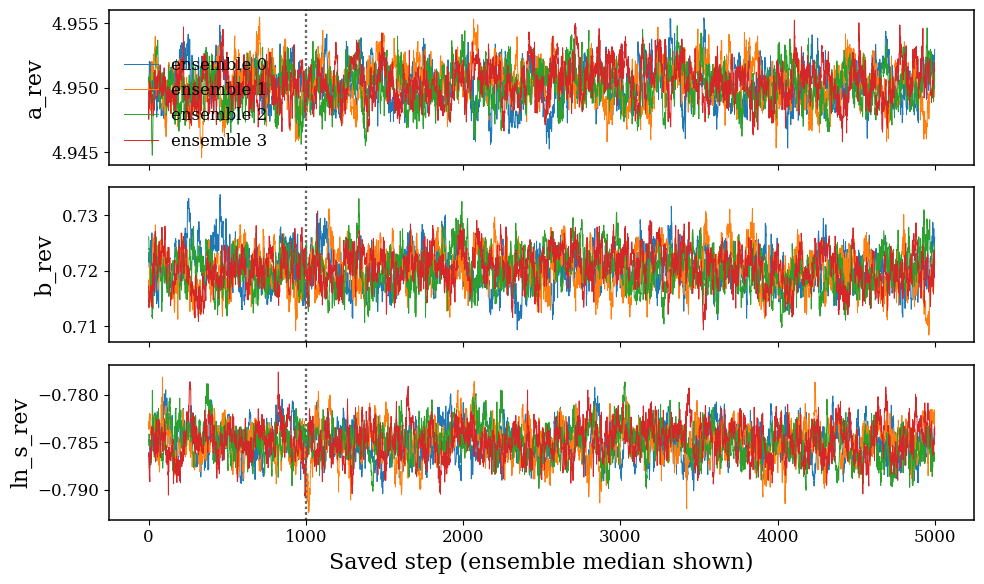

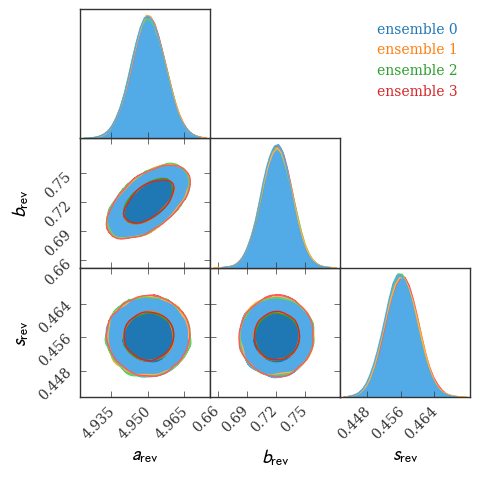

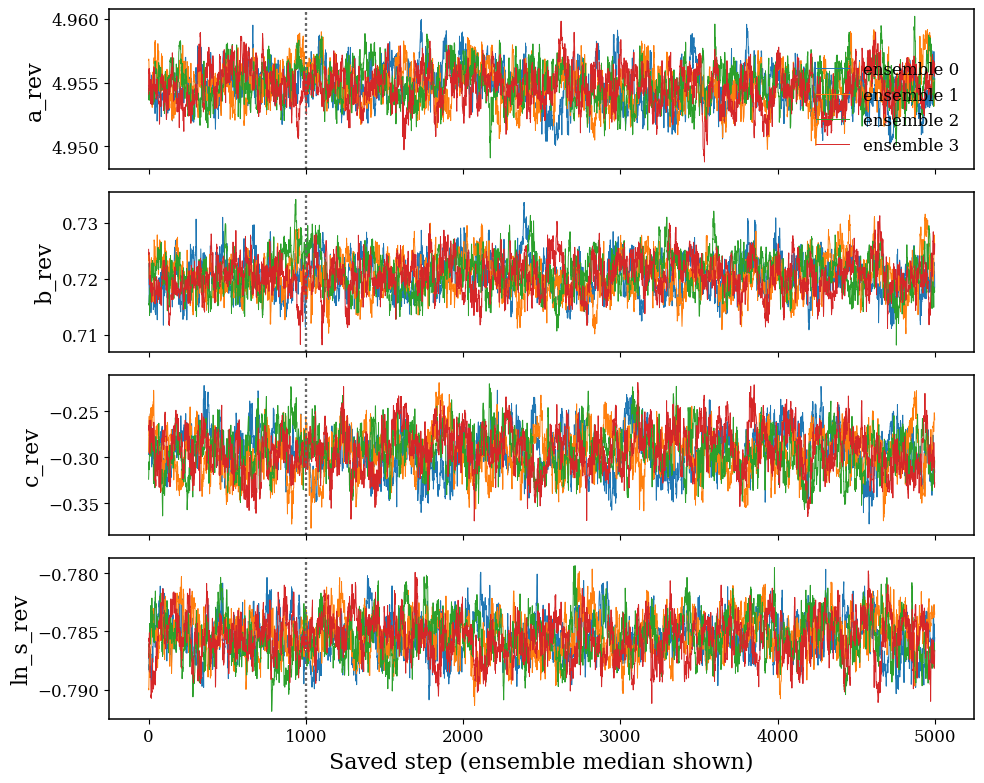

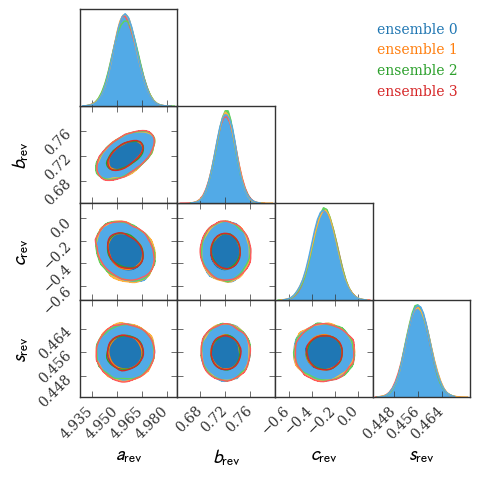

In [5]:
import pygtc
for model in ("noz", "z"):
    names = meta[model]["parameters"]
    fig, axes = plt.subplots(len(names), 1, figsize=(10, 2*len(names)), sharex=True)
    ensembles = []
    for i in range(meta[model]["ensembles"]):
        backend = emcee.backends.HDFBackend(str(FITS/model/f"chain_{i}.h5"), read_only=True)
        chain = backend.get_chain()
        for j, ax in enumerate(axes):
            ax.plot(np.median(chain[:, :, j], axis=1), lw=0.7, label=f"ensemble {i}")
            ax.axvline(meta[model]["burn"], color="0.4", ls=":")
            ax.set_ylabel(names[j])
        retained = chain[meta[model]["burn"]:].reshape(-1, len(names))
        ensembles.append(retained[::max(1, len(retained)//20000)].copy())
    axes[0].legend(frameon=False)
    axes[-1].set_xlabel("Saved step (ensemble median shown)")
    fig.tight_layout()
    save(fig, f"traces_{model}")
    plt.show()
    for sample in ensembles:
        sample[:, -1] = np.exp(sample[:, -1])
    labels = [r"$a_{\rm rev}$", r"$b_{\rm rev}$"]
    if model == "z":
        labels += [r"$c_{\rm rev}$"]
    labels += [r"$s_{\rm rev}$"]
    fig = pygtc.plotGTC(chains=ensembles, paramNames=labels,
        chainLabels=[f"ensemble {i}" for i in range(len(ensembles))],
        figureSize="MNRAS_page",
        customLabelFont={"family": "DejaVu Serif", "size": 14},
        customLegendFont={"family": "DejaVu Serif", "size": 10},
        customTickFont={"family": "DejaVu Serif", "size": 10})
    save(fig, f"corner_{model}")
    plt.show()

In [ ]:
# Forward RM|spec fits: run this cell independently of the reverse-fit cells above.
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'richness_relation').is_dir())
forward_fits = repo / 'catalogs/global_rm_richness_scatter_20261027'
display(pd.read_csv(forward_fits / 'parameters_mean_log.csv'))
display(pd.read_csv(forward_fits / 'model_comparison.csv'))
for model in ('noz', 'z'):
    display(Image(filename=str(repo / 'plots/global_rm_richness_scatter_20261027' / model / f'global_richness_relation_forward_{model}.png')))
